# ZerO-инициализация MLP на MNIST

Ноутбук сравнивает случайную инициализацию, частичную единичную матрицу и ZerO и исследует ограничение ранга из теоремы 1.

Источник формул: [ZerO Initialization, arXiv:2110.12661v3](https://arxiv.org/pdf/2110.12661v3), определения 1–2, теорема 1 и Algorithm 1. 

**Отличие от Figure 3 статьи:** здесь сохранена архитектура исходного примера авторов с четырьмя линейными слоями `784 → 784 → n_h → n_h → 10` и обучением 20 эпох. В статье Figure 3 используется сеть с тремя матрицами; Appendix B описывает `784 → 2048 → 2048 → 10` и 14 эпох. Поэтому данный пример нельзя называть точным воспроизведением Figure 3. Панели построены после обучения с обновлённой нормировкой. Код обучения находится в `zero_experiments/mnist.py`; этот notebook читает сохранённые результаты, без повторного обучения.

## Подготовка окружения

In [1]:
# Зависимости устанавливаются из терминала:
# python -m pip install -r requirements.txt

In [2]:
from pathlib import Path
import csv
from IPython.display import Image, display
from zero_experiments.mnist import MLP, ZerO_Init_on_matrix, Identity_Init_on_matrix, compute_rank

BASE = Path.cwd()
if not (BASE / "zero_experiments").exists():
    BASE = next(p for p in (BASE / "reproduction", BASE / "hw2/reproduction")
                if (p / "zero_experiments").exists())

## Модель и формулы инициализации

Для веса линейного слоя $W\in\mathbb{R}^{P\times Q}$ число строк $P$ — выходная размерность, $Q$ — входная.

Частичная единичная матрица из определения 1:

$$
I^*_{P,Q}=\begin{cases}
[I_P\;0_{P\times(Q-P)}],&P<Q,\\
I_P,&P=Q,\\
\begin{bmatrix}I_Q\\0_{(P-Q)\times Q}\end{bmatrix},&P>Q.
\end{cases}
$$

Матрица Hadamard из определения 2 строится рекурсивно:

$$H_0=[1],\qquad H_m=\begin{bmatrix}H_{m-1}&H_{m-1}\\H_{m-1}&-H_{m-1}\end{bmatrix},\qquad H_m\in\mathbb{R}^{2^m\times2^m}.$$

**Algorithm 1 статьи** задаёт:

$$
W=\begin{cases}
I_P,&P=Q,\\
I^*_{P,Q},&P<Q,\\
c\,I^*_{P,N}H_mI^*_{N,Q},&P>Q,
\end{cases}
\qquad m=\lceil\log_2P\rceil,\quad N=2^m,\quad c=2^{-(m-1)/2}=\sqrt{2/N}.
$$

Для $P>Q$ произведение выбирает первые $P$ строк и $Q$ столбцов $H_m$. Это позволяет не создавать две большие вспомогательные матрицы.

**Различие источников:** официальный MNIST-пример использует $1/\sqrt{N}$, но здесь применяется именно $\sqrt{2/N}$ из Algorithm 1 версии v3. Хотя текст статьи называет преобразование ортонормированным, для полного $cH_m$ с этим множителем $(cH_m)^T(cH_m)=2I$, а не $I$. Формула реализована буквально, без молчаливой замены масштаба.

Сравниваются `Random` (Kaiming normal), `Partial_Identity` и `ZerO`. В модели нет обучаемых смещений.

In [3]:
# Реализация Algorithm 1: zero_experiments/mnist.py.
# Эта ячейка не запускает обучение.

In [4]:
# Класс MLP импортирован из Python-модуля.
# Обучение запускается командой python run_mnist.py.

## Измерение ранга

В теореме 1 исследуется остаточная компонента $W'_\ell=W_\ell-I$. При частичной единичной инициализации и предположениях теоремы:

$$\operatorname{rank}(W'_\ell)\le n_x,\qquad n_x=28\cdot28=784 \quad\text{(уравнение 3)}.$$

Для `l3.weight` измеряем **численный ранг** остатка:

$$r_\tau(W-I)=\sum_i\mathbf{1}\{\sigma_i(W-I)>\tau\},\qquad \tau=10^{-4}.$$

Порог взят из официального MNIST-примера, а не из формулы теоремы. Figure 3 подписывает величину как `rank(W₂)`, тогда как теорема и код примера используют остаток $W-I$; здесь этот выбор указан явно.

Это не stable rank из §5 статьи:

$$\operatorname{srank}(A)=\frac{\lVert A\rVert_F^2}{\lVert A\rVert_2^2}=\frac{\sum_i\sigma_i(A)^2}{\sigma_{\max}(A)^2}.$$

Для нулевой матрицы можно условно положить stable rank равным 0, но **в этом MNIST-эксперименте используется численный ранг**, а не данная дробная мера.

In [5]:
# compute_rank импортирован из zero_experiments/mnist.py.

## Обучение на MNIST

Обучающий цикл адаптирован из примера PyTorch; параметры сохранены из исходного MNIST-ноутбука авторов: batch 64, SGD с начальным шагом 0,1, без momentum и weight decay; 20 эпох; StepLR умножает шаг на 0,7 после 12 эпох.

Для распределения $p_\theta(y\mid x)=\operatorname{softmax}(f_\theta(x))$ используется отрицательное логарифмическое правдоподобие:

$$\mathcal{L}_B(\theta)=-\frac1{|B|}\sum_{(x,y)\in B}\log p_\theta(y\mid x),\qquad\theta_{t+1}=\theta_t-\eta_t\nabla_\theta\mathcal{L}_B(\theta_t).$$

**Различие с теорией статьи:** §2.1 формулирует анализ для квадратичной ошибки $\mathcal{L}=\tfrac12\sum_{\mu=1}^{P}\lVert y^\mu-F(x^\mu)\rVert_2^2$. Практический классификационный пример ниже использует NLL, как официальный MNIST-код. Это разные функции потерь.

Запуск из терминала: `python run_mnist.py --method ZerO --width 2048 --root runs/mnist-new`. Метрики завершённых запусков извлечены из выводов первоначального notebook и сохранены в `runs/mnist/test_history.csv`. Сырые траектории ранга и checkpoints этих запусков не были сохранены; панели ниже отображаются из оригинальных PDF.

In [6]:
# Обучающий цикл вынесен в zero_experiments/mnist.py.
# Пример: python run_mnist.py --method ZerO --width 2048 --root runs/mnist-new

## Проверка ограничения из теоремы 1: адаптация Figure 3

### Левая панель: частичная единичная инициализация при разной ширине

Проверяется, остаётся ли численный ранг $W_3-I$ ниже $n_x=784$ во время обучения. Для ширин 256 и 512 эта граница тривиальна: ранг не превышает размер самой матрицы. Для проверки ограничения при расширении существенны ширины 1024 и 2048.

Набор ширин в исходном примере отличается от легенды Figure 3 статьи (512, 1024, 2048, 4096). Наблюдения ниже относятся к текущему набору, а не к точной копии оригинальной панели.

partial_identity ширина: 256 test accuracy: 98.38%
partial_identity ширина: 512 test accuracy: 98.34%
partial_identity ширина: 1024 test accuracy: 98.34%
partial_identity ширина: 2048 test accuracy: 98.34%


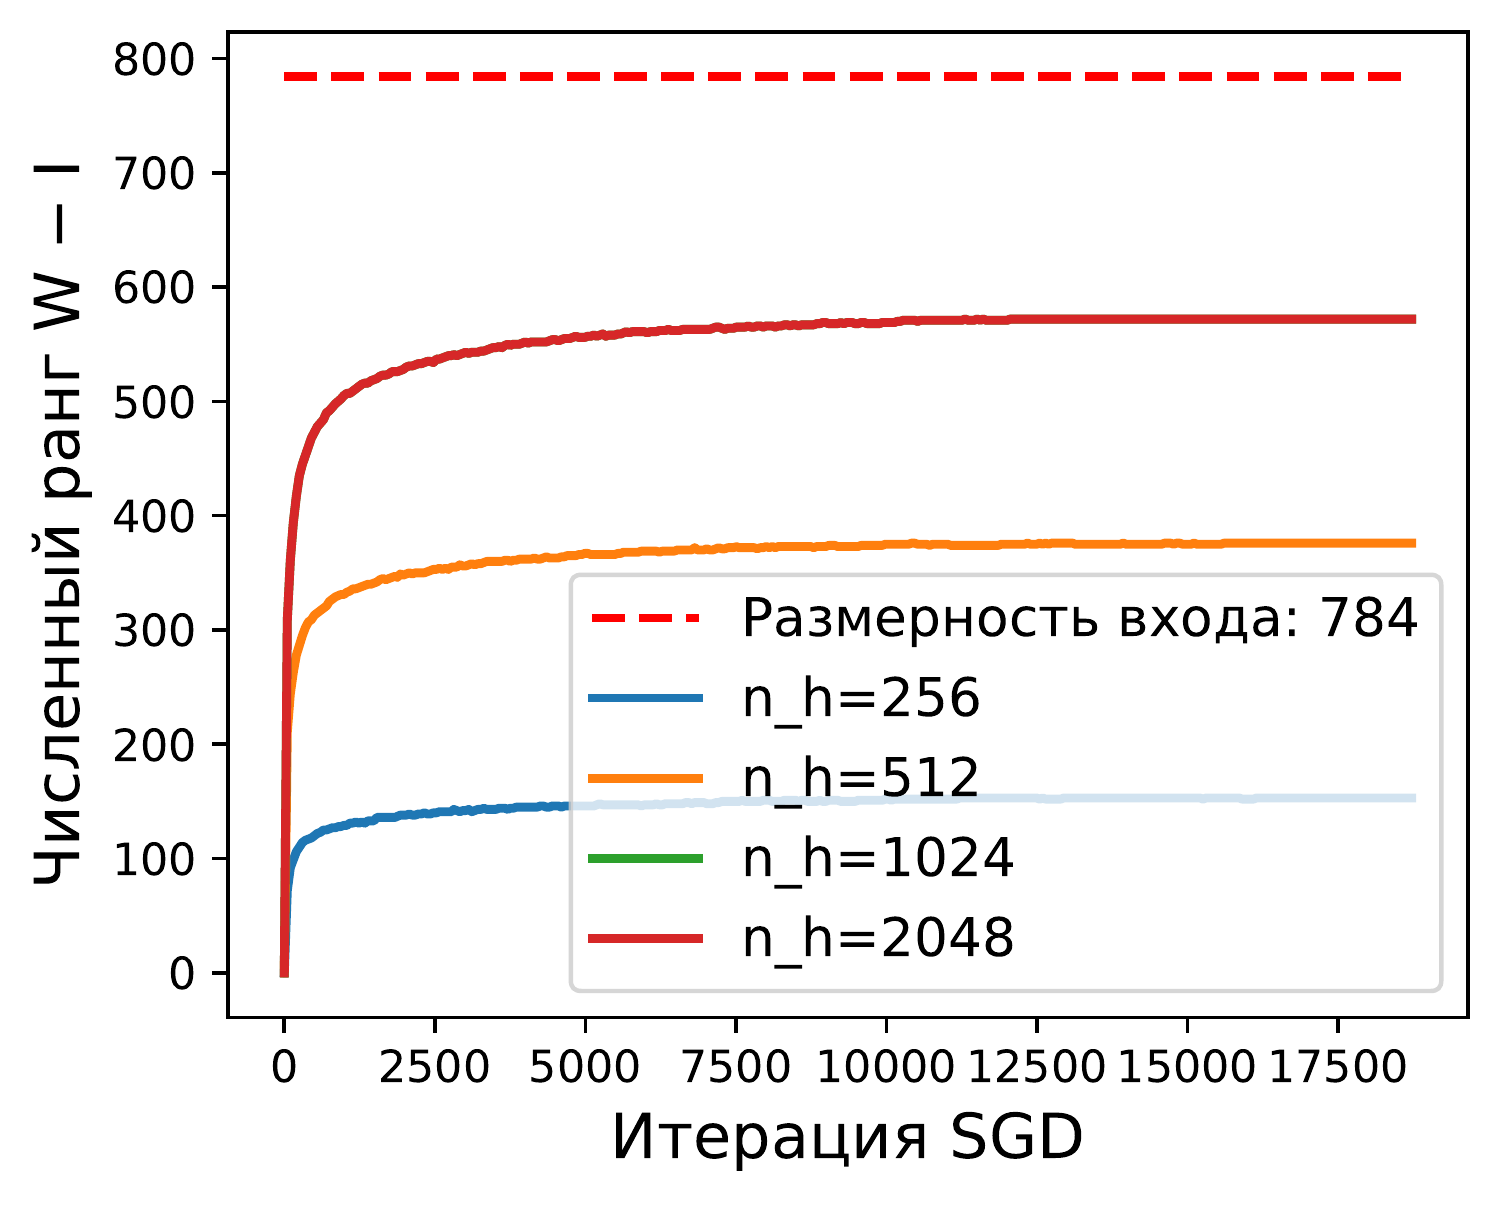

In [7]:
# Сохранённые результаты завершённого обучения; повторное обучение не запускается.
with (BASE / "runs/mnist/test_history.csv").open() as stream:
    results = [row for row in csv.DictReader(stream)
               if row["panel"] == "left" and row["epoch"] == "20"]
for row in results:
    print(row["method"], "ширина:", row["width"], "test accuracy:", row["test_accuracy"] + "%")
display(Image(filename=str(BASE / "runs/mnist/figures/figure_3_left.png")))

### Правая панель: Hadamard и ограничение ранга

При $n_h=2048$ сравниваются Kaiming, partial identity и ZerO. Теорема 1, пункт (iii), допускает

$$\dim\operatorname{span}\{z_\ell(x):x\in\mathbb{R}^{n_x}\}>n_x \quad\text{(уравнение 4)}.$$

По замечанию 2 статьи это эмпирически приводит к нарушению ограничения ранга из уравнения 3. Превышение линии 784 является наблюдаемым результатом обучения, а не обязательным следствием одного вызова инициализации. Здесь измеряется численный ранг остатка `l3.weight − I`.

kaiming ширина: 2048 test accuracy: 98.28%
partial_identity ширина: 2048 test accuracy: 98.34%
zero ширина: 2048 test accuracy: 98.38%


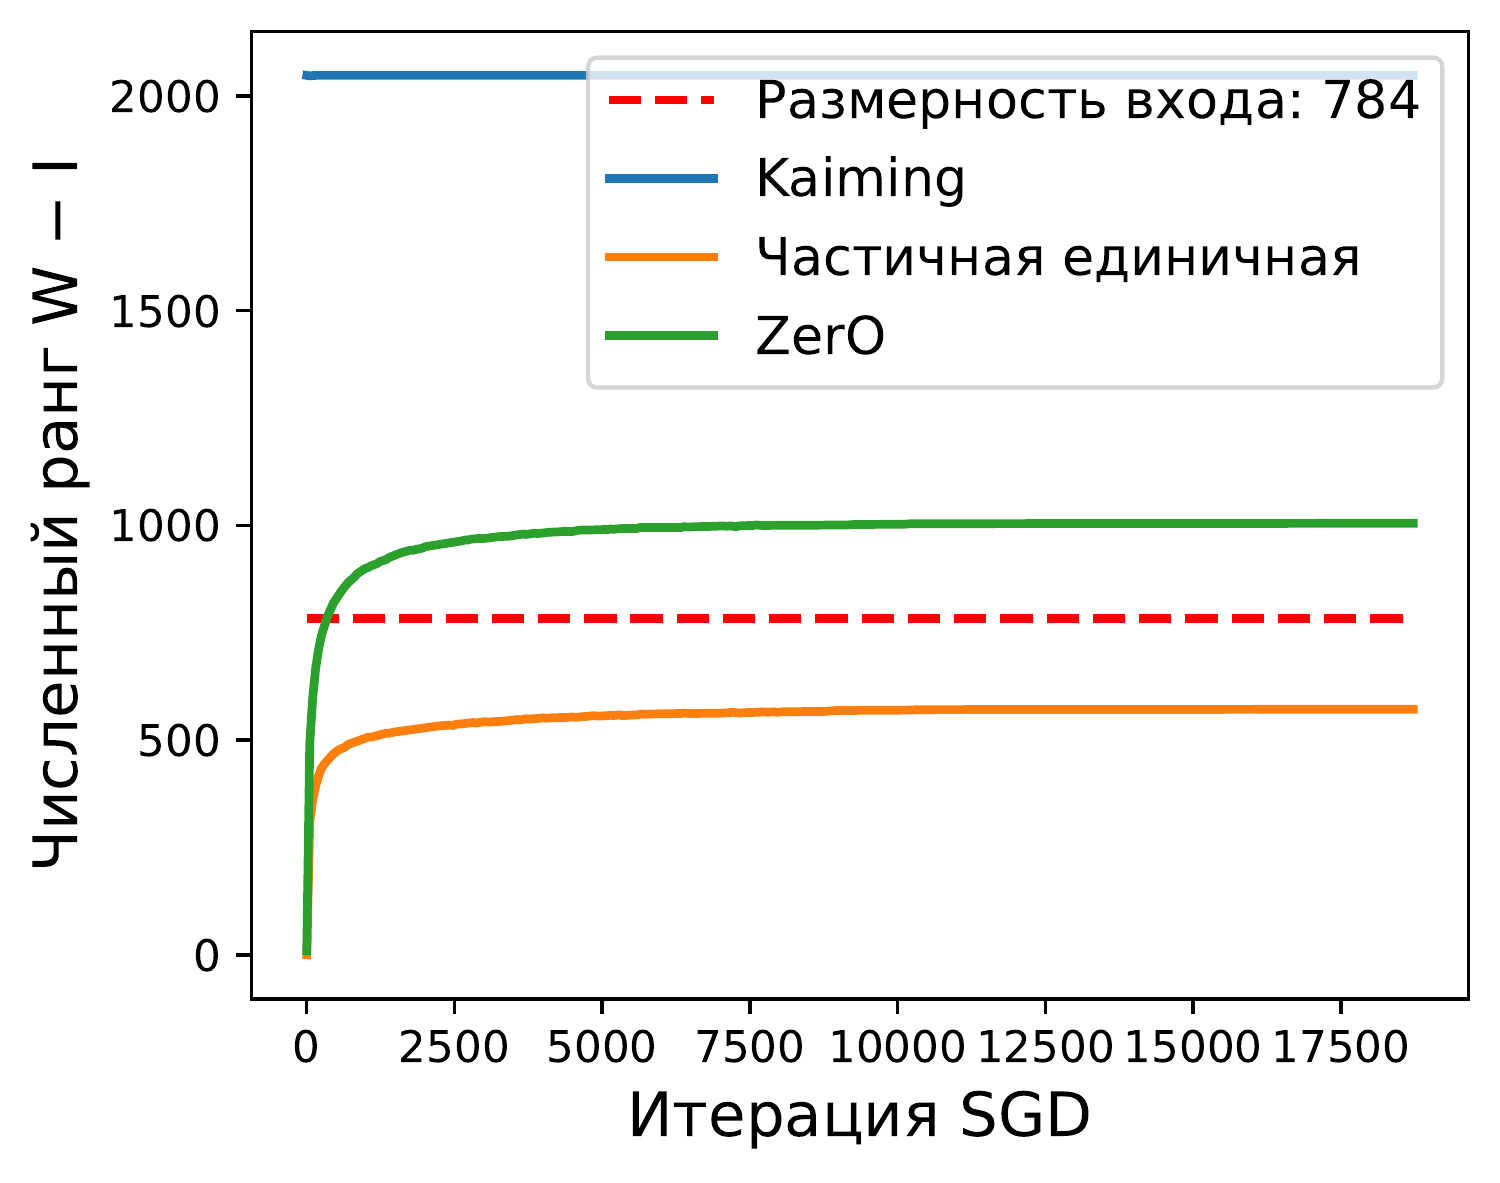

In [8]:
# Сохранённые результаты завершённого обучения; повторное обучение не запускается.
with (BASE / "runs/mnist/test_history.csv").open() as stream:
    results = [row for row in csv.DictReader(stream)
               if row["panel"] == "right" and row["epoch"] == "20"]
for row in results:
    print(row["method"], "ширина:", row["width"], "test accuracy:", row["test_accuracy"] + "%")
display(Image(filename=str(BASE / "runs/mnist/figures/figure_3_right.png")))